In [1]:
%load_ext autoreload
%autoreload 2
%aimport
%matplotlib inline

Modules to reload:
all-except-skipped

Modules to skip:



In [2]:
import os
import sys
nb_dir = os.path.dirname(os.path.split(os.getcwd())[0])
if nb_dir not in sys.path:
    sys.path.append(nb_dir)

In [3]:
from tqdm import tqdm_notebook as tqdm
import pandas as pd
from turicreate import SFrame, load_sframe
from pathlib import Path
import turicreate.aggregate as agg
import numpy as np

In [4]:
diseases_id = load_sframe("Data/diseases_id.csv")
disease_names = pd.read_csv("Data/disease_names.csv")

Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/diseases_id.csv

Parsing completed. Parsed 100 lines in 0.041396 secs.

------------------------------------------------------
Inferred types from first 100 line(s) of file as 
column_type_hints=[str,int]
If parsing fails due to incorrect types, you can correct
the inferred type list above and pass it to read_csv in
the column_type_hints argument
------------------------------------------------------


Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/diseases_id.csv

Parsing completed. Parsed 588 lines in 0.026155 secs.

## Draw Graphs

In [5]:
import json
import os
import matplotlib.pyplot as plt
import pandas as pd
import math
import glob
import ntpath
from tqdm import tqdm
from PIL import Image
from PIL import ImageFont
from PIL import ImageDraw

In [6]:
def chunks(l, n):
    # For item i in a range that is a length of l,
    for i in range(0, len(l), n):
        # Create an index range for l of n items:
        yield l[i:i + n]

def get_d(sf_corr):
    for data in sf_corr.groupby("Disease"):
        if len(data[1]) >5:
            yield data[1].sort_values("Year")

### To PDF

In [7]:
def create_pdf(temp_path,pdf_name):
    # imagelist is the list with all image filenames
    res = []
    image_list = glob.glob(os.path.join(temp_path, f"*.png"))
    image_list.sort()
    for image_path in image_list:
        img = Image.open(image_path).convert("RGB")
        res.append(img)
        os.remove(image_path)

    res[0].save(f"{pdf_name}.pdf", "PDF", resolution=100.0, save_all=True, append_images=res[1:], quality=60, optimize=True)


def draw_probas_graph(graphs, output_name, output_folder, y_fields, time_field):
    rows = math.ceil(math.sqrt(len(graphs)))
    
    fig, axs = plt.subplots(rows, rows, figsize=(14, 14))
    fig.subplots_adjust(left=0.08, right=0.98, wspace=0.3, hspace=0.3)
    titles = [t for t, _ in graphs]
    graphs = [g for _, g in graphs]
    try:
        axs = axs.flatten()
    except:
        axs = [axs]
    for title, data, ax in zip(titles, graphs, axs):

        x = data[time_field]
        for  l, y in y_fields.items():
            if not data[y].isnull().values.all():
                y = np.log(data[y])
                ax.plot(x, y ,linewidth=4  ,label=l)

        ax.xaxis.set_major_locator(plt.MaxNLocator(7, integer=True))
        ax.set_title(title)
        ax.legend()
        ax.grid(True)
        # plt.title(subreddit)
        # plt.ylabel('Average edge strength')
        # plt.xlabel('Graph number')
    plt.savefig(f'{output_folder}/{output_name}.png')
    plt.clf()

## Microsoft Academics

In [8]:
diseases_mag = load_sframe("diseases_mag.sframe")

OSError: /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/diseases_mag.sframe not found.

In [ ]:
def join_pubs_promed(diseases_mag, diseases_id, diseases_occurrences):
    diseases_pub_count = diseases_mag.groupby(["disease","Paper publish year"], {"Number of papers": agg.COUNT()})
    diseases_pub_count_min_5 = diseases_mag[diseases_mag["Ref Number"] > 5].groupby(["disease","Paper publish year"], {"Number of papers (Ref >5)": agg.COUNT()})
    g = diseases_pub_count.join(diseases_pub_count_min_5)
    sf_corr = g.join(diseases_id)
    sf_corr = sf_corr.groupby(["id","Paper publish year"], {"Number of papers":agg.SUM("Number of papers"), "Number of papers (Ref >5)":agg.SUM("Number of papers (Ref >5)")})
    return sf_corr.join(diseases_occurrences, on={"id":"id","Paper publish year":"year"}).to_dataframe()

## Pubmed

In [9]:
 diseases_pubmed = load_sframe("Data/pubmed/diseases_pubmed.sframe")

### Authors Number Per Papaer

In [10]:
diseases_pubmed["authors"] = diseases_pubmed["authors"].apply(lambda x: x.split(";"))

Using default 16 lambda workers.

To maximize the degree of parallelism, add the following code to the beginning of the program:

"turicreate.config.set_runtime_config('TURI_DEFAULT_NUM_PYLAMBDA_WORKERS', 24)"

Note that increasing the degree of parallelism also increases the memory footprint.

In [8]:
diseases_pubmed["number of authors"] = diseases_pubmed["authors"].apply(lambda x: len(x))

In [9]:
total_avg_authors = diseases_pubmed.groupby("id", {"avg number of authors": agg.AVG("number of authors"), "disease":agg.SELECT_ONE("disease")})

In [10]:
total_avg_authors.sort("avg number of authors").print_rows(52)

+----+-----------------------+-------------------------+
| id | avg number of authors |         disease         |
+----+-----------------------+-------------------------+
| 1  |    2.2014742014742    |      dracunculiasis     |
| 37 |   2.3922619047619076  |       paratyphoid       |
| 25 |   2.5140507196710082  |      trichomoniasis     |
| 18 |   2.7926351692774114  |         syphilis        |
| 11 |   3.013377508282809   |         leprosy         |
| 34 |   3.143017037681874   |        diphtheria       |
| 15 |   3.1462060456508323  |         ascaris         |
| 16 |   3.1656794425087025  |         tetanus         |
| 29 |   3.2025316455696218  |       trichuriasis      |
| 5  |   3.2138586000703535  |         trachoma        |
| 14 |   3.2823107049608353  |        gonococcal       |
| 17 |   3.5187598920025986  |       otitis media      |
| 26 |   3.656476002629852   |       yellow fever      |
| 27 |   3.7194541869251485  |       tuberculosis      |
| 24 |   3.7733089579524672  | 

In [11]:
year_avg_authors = diseases_pubmed.groupby(["id", "year"], {"avg number of authors": agg.AVG("number of authors"), "disease":agg.SELECT_ONE("disease")})

In [12]:
year_avg_authors.head(1)

id,year,avg number of authors,disease
13,1928,1.0,pertussis


In [13]:
year_avg_authors = year_avg_authors.rename({"year": "Year","disease":"Disease", "avg number of authors": "Average Number of Authors" })

In [14]:
year_avg_authors = year_avg_authors.remove_column("Disease").join(SFrame(disease_names),{"id":"id"})

In [15]:
year_avg_authors = year_avg_authors.sort(["Disease","Year"])

In [16]:
year_avg_authors

id,Year,Average Number of Authors,Disease
36,1829,1.0,Acute hepatitis
36,1861,1.0,Acute hepatitis
36,1910,1.0,Acute hepatitis
36,1911,1.0,Acute hepatitis
36,1944,3.0,Acute hepatitis
36,1945,2.0,Acute hepatitis
36,1946,1.375,Acute hepatitis
36,1947,1.25,Acute hepatitis
36,1948,1.2727272727272725,Acute hepatitis
36,1949,1.6666666666666665,Acute hepatitis


In [17]:
year_avg_authors_smooth= year_avg_authors[["Disease","Average Number of Authors"]].to_dataframe().groupby("Disease").rolling(5).sum()

In [18]:
year_avg_authors_smooth = year_avg_authors_smooth.reset_index()

In [19]:
year_avg_authors_smooth["Year"] = year_avg_authors.to_dataframe()["Year"]

In [20]:
year_avg_authors_smooth["Average Number of Authors"] = year_avg_authors_smooth["Average Number of Authors"]/5

In [21]:
year_avg_authors_smooth.Year.dtype

dtype('int64')

In [24]:
year_avg_authors_smooth[(year_avg_authors_smooth["Year"]>=1900)&(year_avg_authors_smooth["Year"]<2018)]

,Disease,level_1,Average Number of Authors,Year
2,Acute hepatitis,2,NaN,1910
3,Acute hepatitis,3,NaN,1911
4,Acute hepatitis,4,1.400000,1944
5,Acute hepatitis,5,1.600000,1945
6,Acute hepatitis,6,1.675000,1946
7,Acute hepatitis,7,1.725000,1947
8,Acute hepatitis,8,1.779545,1948
9,Acute hepatitis,9,1.512879,1949
10,Acute hepatitis,10,1.368434,1950
11,Acute hepatitis,11,1.476768,1951


In [100]:
!zip -r curve.zip output/curve/

  adding: output/curve/ (stored 0%)
  adding: output/curve/Acute hepatitis.csv (deflated 52%)
  adding: output/curve/African trypanosomiasis.csv (deflated 62%)
  adding: output/curve/Ascariasis.csv (deflated 57%)
  adding: output/curve/Chagas disease.csv (deflated 53%)
  adding: output/curve/Chlamydial infection.csv (deflated 51%)
  adding: output/curve/Cystic echinococcosis.csv (deflated 51%)
  adding: output/curve/Cysticercosis.csv (deflated 52%)
  adding: output/curve/Dengue.csv (deflated 57%)
  adding: output/curve/Diarrheal diseases.csv (deflated 53%)
  adding: output/curve/Diphtheria.csv (deflated 54%)
  adding: output/curve/Ebola.csv (deflated 55%)
  adding: output/curve/Encephalitis.csv (deflated 54%)
  adding: output/curve/Genital herpes.csv (deflated 52%)
  adding: output/curve/Gonococcal infection.csv (deflated 56%)
  adding: output/curve/Guinea worm disease.csv (deflated 60%)
  adding: output/curve/HIV-AIDS.csv (deflated 54%)
  adding: output/curve/Hookworm disease.csv (def

In [25]:
data = year_avg_authors_smooth[(year_avg_authors_smooth["Disease"]=="Ascariasis")&(year_avg_authors_smooth["Year"]>=1904)][["Year","Average Number of Authors"]]

In [26]:
for d ,d_df in year_avg_authors_smooth[year_avg_authors_smooth["Year"]>=1904].groupby("Disease"):
    d_df[["Year","Average Number of Authors"]].to_csv(f"output/curve/{d.replace('/','-')}.csv",index=False)


In [102]:
data.head(1)

,Year,Average Number of Authors
152,1904,1.0


In [33]:
def adj_r2(y_true, y_pred,p):
    return 1-(1-r2_score(y_true, y_pred))*(len(y_true)-1)/(len(y_true)-p-1)

In [36]:
def exp_func(x, a, b):
    return a * np.exp(b * x)

In [58]:
def linear_func(x, a, b):
    return a + b * x

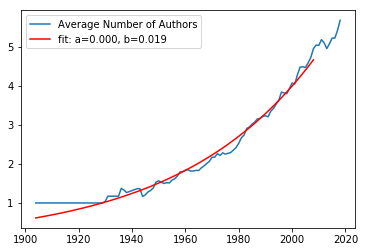

In [30]:
##### import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
n=10
x_train = data["Year"].values[:-n]
y_train = data["Average Number of Authors"].values[:-n]
x_test = data["Year"].values[-n:]
y_test = data["Average Number of Authors"].values[-n:]

plt.plot(data["Year"],  data["Average Number of Authors"])
popt, pcov = curve_fit(exp_func, x_train, y_train, p0=(0, 0), maxfev = 1000)

plt.plot(x_train, exp_func(x_train, *popt), 'r-',
         label='fit: a=%5.3f, b=%5.3f' % tuple(popt))
plt.legend()
plt.show()

In [50]:
year_avg_authors_smooth = year_avg_authors_smooth[year_avg_authors_smooth["Average Number of Authors"].notna()]

In [53]:
[1,2,3][:0]

[]

In [65]:
from sklearn.metrics import mean_squared_error

def calculate_curve(x, y, n=0):
#     x_train = x.values[:-n]
#     y_train = y.values[:-n]
#     x_test = x.values[-n:]
#     y_test = y.values[-n:]
    return curve_fit(exp_func, x, y, p0=(0, 0), maxfev = 6000)


reg = {"Disease":[],"r2":[],"r2_adj":[],"mae":[]}
for d ,d_df in year_avg_authors_smooth[year_avg_authors_smooth["Year"]>=1904].groupby("Disease"):
    x, y = d_df["Year"], d_df["Average Number of Authors"]
    popt, pcov = calculate_curve(x, y)
    y_pred = exp_func(x, *popt)
    reg["Disease"].append(d)
    reg["mae"].append(mean_squared_error(y, y_pred))

    reg["r2"].append(r2_score(y, y_pred))
    reg["r2_adj"].append(adj_r2(y, y_pred, 2))

In [66]:
pd.DataFrame(reg)

,Disease,r2,r2_adj,mae
0,Acute hepatitis,0.988247,0.987925,0.034494
1,African trypanosomiasis,0.918316,0.915638,0.163371
2,Ascariasis,0.987989,0.987749,0.023423
3,Chagas disease,0.972700,0.971897,0.056435
4,Chlamydial infection,0.983684,0.982975,0.019853
5,Cystic echinococcosis,0.991903,0.991665,0.019879
6,Cysticercosis,0.930421,0.928565,0.138815
7,Dengue,0.966990,0.966272,0.092180
8,Diarrheal diseases,0.979267,0.978755,0.034933
9,Diphtheria,0.970800,0.970283,0.069027


In [64]:
pd.DataFrame(reg)

,Disease,r2,r2_adj,mae
0,Acute hepatitis,0.977131,0.976504,0.067119
1,African trypanosomiasis,0.863562,0.859088,0.272882
2,Ascariasis,0.876427,0.873956,0.240986
3,Chagas disease,0.946708,0.945140,0.110166
4,Chlamydial infection,0.960598,0.958885,0.047944
5,Cystic echinococcosis,0.959249,0.958051,0.100045
6,Cysticercosis,0.921297,0.919198,0.157019
7,Dengue,0.863473,0.860505,0.381245
8,Diarrheal diseases,0.898854,0.896356,0.170421
9,Diphtheria,0.850151,0.847499,0.354230


In [34]:
from sklearn.metrics import r2_score
y_pred = exp_func(x_train, *popt)
r2_score(y_train, y_pred)


0.9821739687672454

In [35]:
adj_r2(y_train, y_pred,2)

0.9817778347398508

In [32]:
mean_squared_error(y_train, y_pred)

0.022477262590302072

In [225]:
from sklearn.metrics import r2_score
y_pred = exp_func(x_test, *popt)
r2_score(y_test, y_pred)


0.21788087651610888

In [226]:
from sklearn.metrics import mean_squared_error
mean_squared_error(y_test, y_pred)

0.03266162723198389

In [227]:
from sklearn.metrics import r2_score
y_pred = exp_func(data["Year"], *popt)
r2_score(data["Average Number of Authors"], y_pred)


0.9879670643959606

In [1]:
r2_score

NameError: name 'r2_score' is not defined

In [216]:
mean_squared_error(data["Average Number of Authors"], y_pred)

0.03728419598595951

In [51]:
from scipy import stats

stats.kstest(year_avg_authors_smooth[(year_avg_authors_smooth["Disease"]=="Ascariasis")&(year_avg_authors_smooth["Year"]>=1904)]["Average Number of Authors"],'powerlaw')

TypeError: _parse_args() missing 1 required positional argument: 'a'

ValueError: x and y must have same first dimension, but have shapes (100,) and (1,)

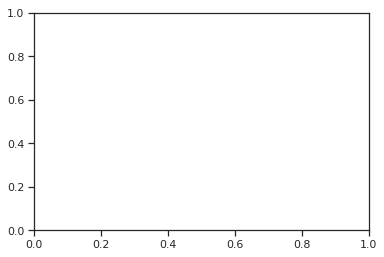

In [50]:
from scipy.stats import powerlaw
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 1)
x = np.linspace(expon.ppf(0.01),
              expon.ppf(0.99), 100)
ax.plot(x,powerlaw(x),
         'r-', lw=5, alpha=0.6, label='expon pdf')

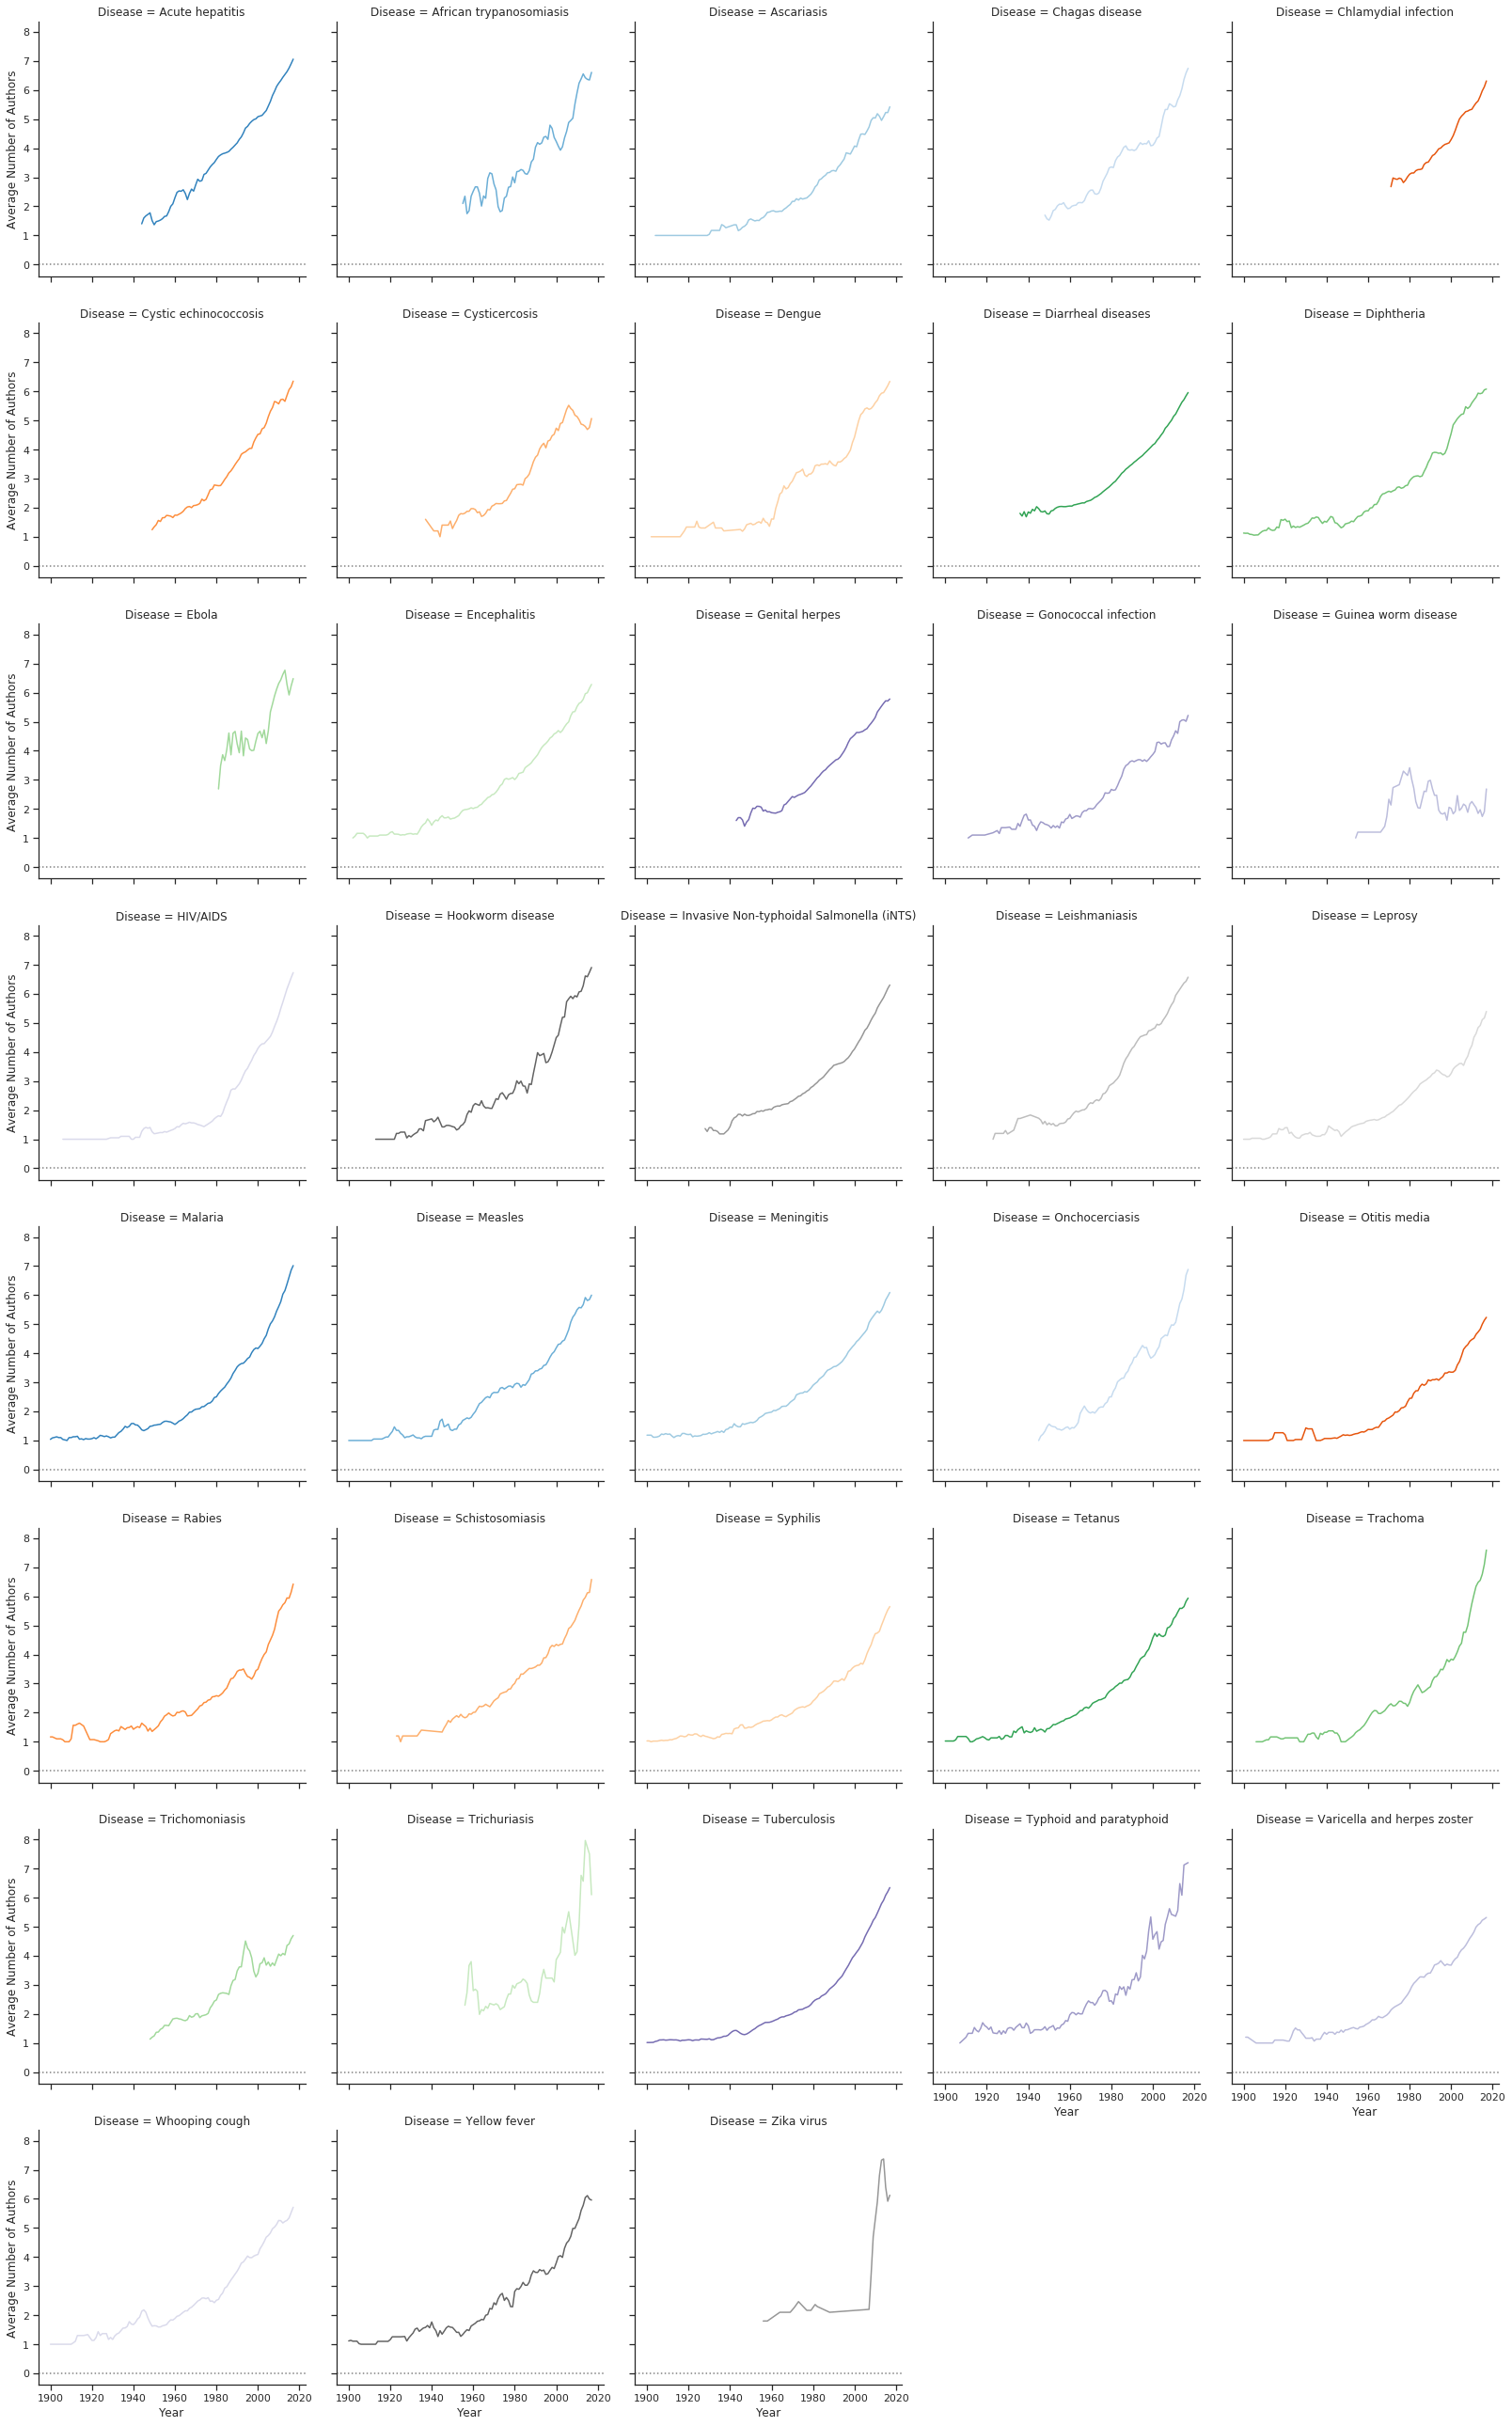

In [31]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")


# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(year_avg_authors_smooth[(year_avg_authors_smooth["Year"]>=1900)&(year_avg_authors_smooth["Year"]<2018)], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "Average Number of Authors")

# Adjust the tick positions and labels
# grid.set(xticks=np.arange(5), yticks=[-3, 3],
#          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

In [20]:
output_folder = "output"
temp_folder = "temp"

os.makedirs(output_folder, exist_ok=True)
des = list(get_d(year_avg_authors.to_dataframe(), diseases_id))
for i, curr_f in enumerate(tqdm(chunks(des, 9), total=((len(des) // 9)+1))):
    draw_probas_graph(curr_f, str(i), temp_folder,{"avg number of authors":"avg number of authors"}, "year")
create_pdf(temp_folder,f"{output_folder}/authors_year2")

100%|██████████| 5/5 [00:05<00:00,  1.14s/it]


<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

#### Diseases Researchers

In [23]:
diseases_pubmed = diseases_pubmed.stack("authors",new_column_name="author")

In [28]:
diseases_researchers = diseases_pubmed.groupby("id",  {"disease":agg.SELECT_ONE("disease"), "author_count": agg.COUNT_DISTINCT("author")}).sort('author_count',ascending=False)
diseases_researchers

id,disease,author_count
12,aids,313988
27,tuberculosis,196977
36,hepatitis b,175995
6,escherichia coli,155609
28,salmonella,78200
32,malaria,78160
22,meningitis,72717
31,sleeping sickness,52627
35,herpes simplex,44425
10,dengue,33343


In [29]:
diseases_researchers.save("output/diseases_researchers_pubmed.csv","csv")

In [26]:
diseases_researchers_miner = diseases_miner.groupby("id",  {"disease":agg.SELECT_ONE("disease"), "author_count": agg.COUNT_DISTINCT("author.id")}).sort('author_count',ascending=False)
diseases_researchers_miner

NameError: name 'diseases_miner' is not defined

In [100]:
diseases_researchers_miner.save("diseases_researchers_miner.csv","csv")

## Aminer

In [24]:
diseases_miner = load_sframe("Data/aminer/diseases_aminer.sframe")
diseases_miner["year"] = diseases_miner["year"].astype(int)

In [26]:
diseases_miner["n_citation"].mean()

6.260350375358164

## Semantic Scholar

In [11]:
diseases_sm = load_sframe("Data/sm/diseases_sm.sframe")

#### Authors Number Per Papaer

In [12]:
diseases_sm["number of authors"] = diseases_sm["authors"].apply(lambda x: len(x))

In [13]:
total_avg_authors = diseases_sm.groupby("id", {"avg number of authors": agg.AVG("number of authors"),"Count": agg.COUNT(), "disease":agg.SELECT_ONE("disease")})

In [14]:
total_avg_authors.sort("avg number of authors")

id,avg number of authors,Count,disease
202,1.0,1,Gastrodiscoidiasis
103,1.75,4,Spotted fevers
96,2.0,1,Clostridioides difficilecolitis ...
200,2.6666666666666665,6,Echinostomiasis
221,2.6666666666666665,3,Fasciolopsiasis
297,2.913043478260869,69,Granuloma inguinale
189,2.9166666666666665,12,Ornithosis
311,2.9230769230769234,13,Wesselsbron
167,3.142857142857143,7,Nanophyetiasis
70,3.185185185185184,135,Free-living amoebae


In [15]:
total_avg_authors.sort("Count", False)

id,avg number of authors,Count,disease
92,5.505552542852494,127239,HIV/AIDS
259,5.562823681100261,46535,Tuberculosis
17,4.71313055333555,42542,Escherichia coli diarrhea
266,6.27355457311825,34834,Influenza
286,6.022207160513485,25082,Malaria
88,6.7797816611348605,25007,Hepatitis C
53,6.280845599130694,20246,Hepatitis B
302,5.723867375348012,19755,Pneumonia
79,5.422475773679238,12796,Dengue
252,4.8210074123988935,11872,Urinary tract


In [16]:
total_avg_authors = total_avg_authors[total_avg_authors["Count"]>50]

In [17]:
total_avg_authors["id"]

dtype: int
Rows: ?
[232, 71, 291, 263, 292, 65, 67, 293, 151, 121, 160, 259, 91, 243, 256, 217, 70, 135, 218, 239, 158, 307, 27, 207, 49, 125, 42, 110, 229, 301, 28, 294, 5, 184, 109, 32, 174, 55, 92, 203, 333, 224, 7, 279, 137, 114, 193, 69, 261, 47, 90, 66, 170, 322, 83, 163, 306, 124, 250, 73, 231, 310, 60, 247, 164, 54, 26, 51, 252, 14, 277, 321, 331, 249, 329, 41, 120, 146, 74, 93, 284, 213, 33, 24, 2, 268, 123, 265, 19, 255, 314, 81, 230, 175, 45, 72, 191, 9, 199, 194, ... ]

In [18]:
total_avg_authors[total_avg_authors["Count"]>50].sort("avg number of authors").save("output/Collab/avg_authors.csv")

In [19]:
year_avg_authors = diseases_sm.filter_by(total_avg_authors["id"], "id").groupby(["id", "year"], {"Average Number of Authors": agg.AVG("number of authors"),"Count": agg.COUNT(), "disease":agg.SELECT_ONE("disease")})

In [20]:
year_avg_authors = year_avg_authors.rename({"year": "Year","disease":"Disease" })

In [21]:
year_avg_authors = year_avg_authors.sort(["Disease","Year"])

In [22]:
year_avg_authors_smooth= year_avg_authors[["Disease","Average Number of Authors"]].to_dataframe().groupby("Disease").rolling(5, min_periods=1).mean()

In [23]:
year_avg_authors_smooth = year_avg_authors_smooth.reset_index()

In [24]:
year_avg_authors_smooth["Year"] = year_avg_authors.to_dataframe()["Year"]

In [38]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")
def create_gird(df, col, hue,x,y):

    # Initialize a grid of plots with an Axes for each walk
    grid = sns.FacetGrid(df, col=col, hue=hue, palette="tab20c",
                         col_wrap=5, height=4.5)

    # Draw a horizontal line to show the starting point
    grid.map(plt.axhline, y=0, ls=":", c=".5")

    # Draw a line plot to show the trajectory of each random walk
    grid.map(plt.plot, x, y)

    # Adjust the tick positions and labels
    # grid.set(xticks=np.arange(5), yticks=[-3, 3],
    #          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

    # Adjust the arrangement of the plots
    grid.fig.tight_layout(w_pad=1)
    return grid

In [30]:
year_avg_authors_smooth = year_avg_authors_smooth[year_avg_authors_smooth["Disease"].isin(["SARS","MERS Coronavirus"])]

In [41]:
year_avg_authors_smooth = year_avg_authors_smooth[year_avg_authors_smooth["Year"]>2011]

In [43]:
year_avg_authors_smooth

,Disease,level_1,Average Number of Authors,Year
4858,MERS Coronavirus,4858,1.000000,2012.0
4859,MERS Coronavirus,4859,4.480519,2013.0
4860,MERS Coronavirus,4860,5.696346,2014.0
4861,MERS Coronavirus,4861,5.921941,2015.0
4862,MERS Coronavirus,4862,6.430886,2016.0
4863,MERS Coronavirus,4863,7.785298,2017.0
4864,MERS Coronavirus,4864,8.197852,2018.0
4865,MERS Coronavirus,4865,8.096196,2019.0
7460,SARS,7460,5.630967,2012.0
7461,SARS,7461,5.526394,2013.0


In [42]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Corona/corona_authors.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(year_avg_authors_smooth))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        create_gird(pd.concat(curr_f),"Disease","Disease","Year", "Average Number of Authors")
#         plt.title('Page')
        pdf.savefig()
        plt.close()
#         plt.clf()



100%|██████████| 1/1 [00:00<00:00,  2.41it/s]


<Figure size 576x432 with 0 Axes>

#### Diseases Researchers

In [45]:
diseases_sm.head(1)

Columns:
	paper id	str
	sources	list
	title	str
	venue	str
	year	int
	journalName	str
	inCitations	dict
	authors	list
	Normalized paper title	str
	id	int
	disease	str
	pmid	str
	number of authors	int

Rows: 1

Data:
+-------------------------------+-----------+-------------------------------+
|            paper id           |  sources  |             title             |
+-------------------------------+-----------+-------------------------------+
| c491f893ebdd0b423e9a5f4689... | [Medline] | Longitudinal genomic surve... |
+-------------------------------+-----------+-------------------------------+
+----------------+------+-------------+-------------------------------+
|     venue      | year | journalName |          inCitations          |
+----------------+------+-------------+-------------------------------+
| Genome Biology | 2017 |             | {'028792dcf651f924ecf50c40... |
+----------------+------+-------------+-------------------------------+
+-------------------------------+-------------------------------+-----+---------+
|            authors            |     Normalized paper title    |  id | disease |
+-------------------------------+-------------------------------+-----+---------+
| [{'name': 'Gustavo Coutinh... | longitudinal genomic surve... | 286 | Malaria |
+-------------------------------+-------------------------------+-----+---------+
+----------+-------------------+
|   pmid   | number of authors |
+----------+-------------------+
| 28454557 |         13        |
+----------+-------------------+
[1 rows x 13 columns]

In [44]:
diseases_sm_authors = diseases_sm.stack("authors",new_column_name="author").unpack("author")

In [45]:
len(diseases_sm_authors)

3568259

In [46]:
diseases_sm_authors = diseases_sm_authors.stack("author.ids",new_column_name="author.ids")

In [47]:
diseases_researchers = diseases_sm_authors.groupby("id",  {"disease":agg.SELECT_ONE("disease"), "author_count": agg.COUNT_DISTINCT("author.ids")}).sort('author_count',ascending=False)
diseases_researchers

id,disease,author_count
92,HIV/AIDS,272108
259,Tuberculosis,136418
17,Escherichia coli diarrhea,118429
266,Influenza,105272
88,Hepatitis C,83348
302,Pneumonia,74204
53,Hepatitis B,73706
286,Malaria,66989
252,Urinary tract,40538
79,Dengue,39432


In [50]:
diseases_researchers.save("output/Collab/diseases_researchers_sm.csv","csv")

In [49]:
!cp -avr ../Infectious\ Disease\ Trends ../Coronavirus

'../Infectious Disease Trends' -> '../Coronavirus'
'../Infectious Disease Trends/output' -> '../Coronavirus/output'
'../Infectious Disease Trends/output/gdb.pdf' -> '../Coronavirus/output/gdb.pdf'
'../Infectious Disease Trends/output/.ipynb_checkpoints' -> '../Coronavirus/output/.ipynb_checkpoints'
'../Infectious Disease Trends/output/.ipynb_checkpoints/gdb-checkpoint.pdf' -> '../Coronavirus/output/.ipynb_checkpoints/gdb-checkpoint.pdf'
'../Infectious Disease Trends/output/.ipynb_checkpoints/authors_year-checkpoint.pdf' -> '../Coronavirus/output/.ipynb_checkpoints/authors_year-checkpoint.pdf'
'../Infectious Disease Trends/output/.ipynb_checkpoints/disease_citations_year-checkpoint.pdf' -> '../Coronavirus/output/.ipynb_checkpoints/disease_citations_year-checkpoint.pdf'
'../Infectious Disease Trends/output/.ipynb_checkpoints/disease_citations_year2-checkpoint.pdf' -> '../Coronavirus/output/.ipynb_checkpoints/disease_citations_year2-checkpoint.pdf'
'../Infectious Disease Trends/output/.ip